In [1]:
import torch
import pyro
from mmbo.training import do_svi
from mmbo.nn import RegBNN, LayeredRegBNN, RegBNNGuide, LayeredRegBNNGuide
from mmbo.nn import posterior_samples
from mmbo.nn import predictor
from mmbo_v1.nn import RegBNN as RegBNN_v1, LayeredRegBNN as LayeredRegBNN_v1, RegBNNGuide as RegBNNGuide_v1, LayeredRegBNNGuide as LayeredRegBNNGuide_v1
from mmbo_v1.training import do_svi as do_svi_v1
from mmbo_v1.nn import posterior_samples as posterior_samples_v1
from mmbo_v1.nn import predictor as predictor_v1

from mmbo.examples.demo import paciorek_demo

import matplotlib.pyplot as plt
from scipy.stats import ks_2samp
import math

# Unpack the included data from dictionary
X_train_main = paciorek_demo["X_train_main"]
X_train_mm =   paciorek_demo["X_train_mm"]
X_test =       paciorek_demo["X_test"]
Y_train_main = paciorek_demo["Y_train_main"]
Y_train_mm =   paciorek_demo["Y_train_mm"]
Y_test_main =  paciorek_demo["Y_test_main"]
Y_test_mm =    paciorek_demo["Y_test_mm"]

c:\Users\itaylor\Documents\DS4MEMS\code\mmbo\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
# Make sure we're using the package version we want to
from importlib.metadata import version
print(version("mmbo"))
print(version("mmbo_v1"))

2.0.0
1.0.0


In [3]:
learning_rate = 0.001
n_samples = 1000 # Number of posterior samples to use
# reproducibility 
seed = 2028

## Version 2

In [4]:
# reproducibility
torch.manual_seed(seed)

In [5]:

# Initialize the model: from_data method uses training data to set input/output
# dimensions and normalizer layersl It also stores the training data within the model,
# so that no data needs to be passed during training.
model_single = RegBNN.from_data(X_train_main, Y_train_main, hidden_widths = [256, 256], prior_variance = 0.01)

# Initialize the guide: uses model to reference layers and their widths, and
# priors if custom hyperparemters are supplied.
guide_single = RegBNNGuide(model_single)

In [6]:
torch.manual_seed(seed)

In [7]:


adam = pyro.optim.Adam({"lr": learning_rate})
elbo = pyro.infer.Trace_ELBO(num_particles = 1)
# model,guide are created by code like above
svi = pyro.infer.SVI(model_single, guide_single, adam, elbo)

# The optional params argument can be used to restart training from a
# previously returned set of parameters (e.g. with a smaller learning
# rate).
params_single, losses_single = do_svi(svi, params = None, X_train = X_train_main, Y_train = Y_train_main)

2026-11-04 16:08:53 - Start


c:\Users\itaylor\Documents\DS4MEMS\code\mmbo\.venv\Lib\site-packages\pyro\distributions\torch_distribution.py:49: UserWarning: Singular sample detected.
  self.rsample(sample_shape)


2026-11-04 16:09:17 - Step 1000, Elbo loss: 48461.4 +/- 29443.2 (slope = -50507.262 +/- 434.584 loss/k-iter, p-value = 0.000) + 
2026-11-04 16:09:40 - Step 2000, Elbo loss: 16741.0 +/- 10130.7 (slope = -17364.546 +/- 155.827 loss/k-iter, p-value = 0.000) + 
2026-11-04 16:10:04 - Step 3000, Elbo loss: 5978.7 +/- 3391.9 (slope = -5810.549 +/- 53.612 loss/k-iter, p-value = 0.000) + 
2026-11-04 16:10:42 - Step 4000, Elbo loss: 2351.6 +/- 1160.7 (slope = -1985.693 +/- 19.478 loss/k-iter, p-value = 0.000) + 
2026-11-04 16:11:27 - Step 5000, Elbo loss: 1104.8 +/- 406.1 (slope = -692.713 +/- 7.608 loss/k-iter, p-value = 0.000) + 
2026-11-04 16:12:09 - Step 6000, Elbo loss: 660.3 +/- 152.9 (slope = -256.619 +/- 4.118 loss/k-iter, p-value = 0.000) + 
2026-11-04 16:12:55 - Step 7000, Elbo loss: 497.0 +/- 60.9 (slope = -95.359 +/- 2.858 loss/k-iter, p-value = 0.000) + 
2026-11-04 16:13:37 - Step 8000, Elbo loss: 434.2 +/- 32.6 (slope = -39.197 +/- 2.567 loss/k-iter, p-value = 0.000) + 
2026-11-04 

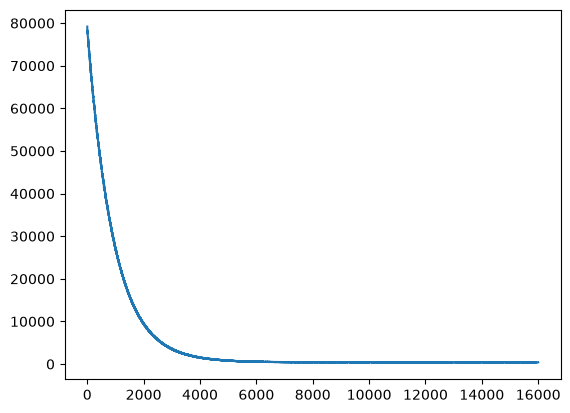

In [8]:
plt.plot(losses_single)

In [9]:

samples_single = posterior_samples(guide_single, params_single, n_samples, X_train = X_train_main, Y_train = Y_train_main)

In [10]:
pred_single = predictor(model_single, samples_single)
Y_test_pred_single = pred_single(X_test)
Y_train_pred_single = pred_single(X_train_main)

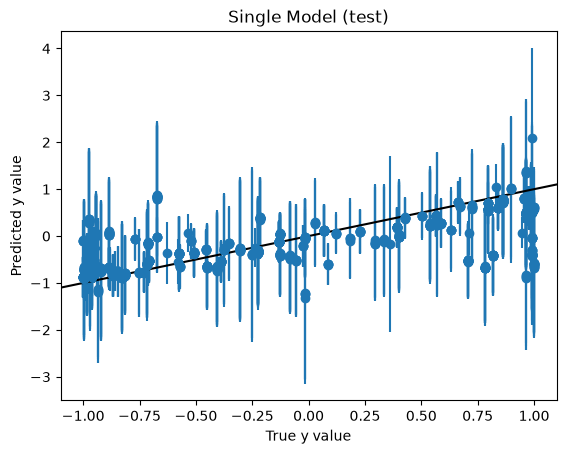

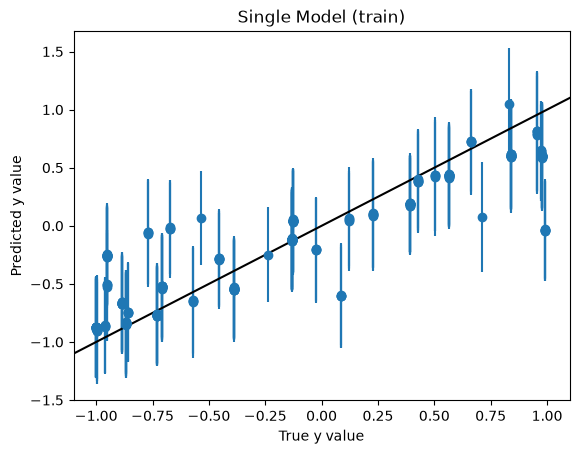

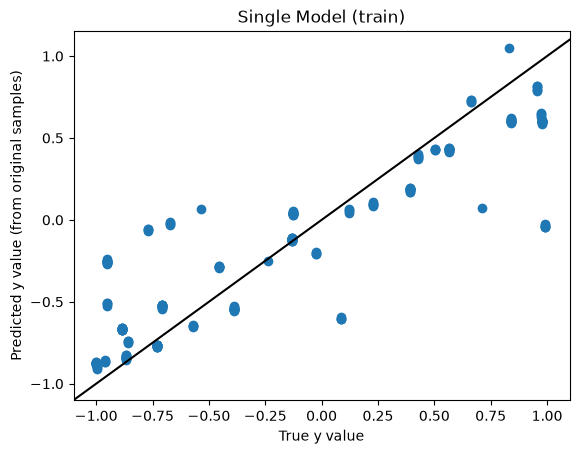

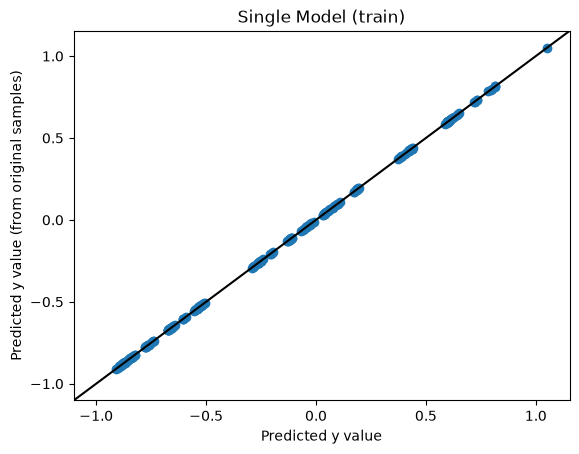

In [11]:
plt.errorbar(Y_test_main, Y_test_pred_single.mean(dim=0).squeeze(), yerr = 1.96 * Y_test_pred_single.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_test_main, Y_test_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (test)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.errorbar(Y_train_main, Y_train_pred_single.mean(dim=0).squeeze(), yerr = 1.96 * Y_train_pred_single.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_train_main, Y_train_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.scatter(Y_train_main, samples_single["train/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

plt.scatter(Y_train_pred_single.mean(dim=0), samples_single["train/mu"].mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model (train)")
plt.xlabel("Predicted y value")
plt.ylabel("Predicted y value (from original samples)")
plt.show()

## Version 1

In [12]:
# reproducibility
torch.manual_seed(seed)

In [13]:

# Initialize the model: from_data method uses training data to set input/output
# dimensions and normalizer layersl It also stores the training data within the model,
# so that no data needs to be passed during training.
model_single_v1 = RegBNN_v1.from_data(X_train_main, Y_train_main, hidden_widths = [256, 256], prior_variance = 0.01)

# Initialize the guide: uses model to reference layers and their widths, and
# priors if custom hyperparemters are supplied.
guide_single_v1 = RegBNNGuide_v1(model_single_v1)

In [14]:
torch.manual_seed(seed)

In [15]:
adam_v1 = pyro.optim.Adam({"lr": learning_rate})
elbo_v1 = pyro.infer.Trace_ELBO(num_particles = 1)
# model,guide are created by code like above
svi_v1 = pyro.infer.SVI(model_single_v1, guide_single_v1, adam_v1, elbo_v1)

# The optional params argument can be used to restart training from a
# previously returned set of parameters (e.g. with a smaller learning
# rate).
params_single_v1, losses_single_v1 = do_svi_v1(svi_v1, params = None, X_train = X_train_main, Y_train = Y_train_main)

2026-11-04 16:19:09 - Start


ValueError: Expected parameter scale (Tensor of shape (256, 257)) of distribution Normal(loc: torch.Size([256, 257]), scale: torch.Size([256, 257])) to satisfy the constraint GreaterThan(lower_bound=0.0), but found invalid values:
tensor([[0.0366, 0.3943, 0.9263,  ..., 0.8337, 0.0148, 0.3564],
        [0.0340, 0.1308, 0.6227,  ..., 0.6931, 0.3456, 0.4548],
        [0.1329, 0.6506, 0.4596,  ..., 0.5011, 0.8386, 0.6897],
        ...,
        [0.4936, 0.9365, 0.8645,  ..., 0.5215, 0.7269, 0.9010],
        [0.7726, 0.8450, 0.8056,  ..., 0.3998, 0.8833, 0.5285],
        [0.6896, 0.2499, 0.4911,  ..., 0.2815, 0.7678, 0.7698]],
       grad_fn=<AddBackward0>)
        Trace Shapes:              
         Param Sites:              
       layers.0.0.loc 256   5      
     layers.0.0.scale 256   5      
 layers.0.1.scale_val              
       layers.1.0.loc 256 257      
     layers.1.0.scale 256 257      
        Sample Sites:              
   layers.0.0.bW dist       | 256 5
                

In [ ]:
plt.plot(losses_single_v1)

In [ ]:
samples_single_v1 = posterior_samples_v1(guide_single_v1, params_single_v1, n_samples, X_train = X_train_main, Y_train = Y_train_main)

In [ ]:
pred_single_v1 = predictor_v1(model_single_v1, samples_single_v1)
Y_test_pred_single_v1 = pred_single_v1(X_test)
Y_train_pred_single_v1 = pred_single_v1(X_train_main)

In [ ]:
plt.errorbar(Y_test_main, Y_test_pred_single_v1.mean(dim=0).squeeze(), yerr = 1.96 * Y_test_pred_single_v1.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_test_main, Y_test_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model _v1 (test)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

plt.errorbar(Y_train_main, Y_train_pred_single_v1.mean(dim=0).squeeze(), yerr = 1.96 * Y_train_pred_single_v1.std(dim=0).squeeze(), linestyle="none", marker="o")
#plt.scatter(Y_train_main, Y_train_pred_single.mean(dim=0))
plt.axline([-1,-1], [1,1], c="black")
plt.title("Single Model _v1 (train)")
plt.xlabel("True y value")
plt.ylabel("Predicted y value")
plt.show()

## Compare the distributions of stuff

In [ ]:
idx = 0
plt.hist(Y_test_pred_single[:,idx,0], label="v2")
plt.hist(Y_test_pred_single_v1[:,idx,0], label="v1")
plt.title("Test")
plt.show()

plt.ecdf(Y_test_pred_single[:,idx,0], label="v2")
plt.ecdf(Y_test_pred_single_v1[:,idx,0], label="v1")
plt.title("Test")
plt.show()

plt.hist(Y_train_pred_single[:,idx,0], label="v2")
plt.hist(Y_train_pred_single_v1[:,idx,0], label="v1")
plt.title("Train")
plt.show()

plt.ecdf(Y_train_pred_single[:,idx,0], label="v2")
plt.ecdf(Y_train_pred_single_v1[:,idx,0], label="v1")
plt.title("Train")
plt.show()

In [ ]:
# Compute KS statistics of all of the predictions for train and test points

ks_stats_train = torch.zeros((Y_train_pred_single.shape[-2]))
ks_stats_test = torch.zeros((Y_test_pred_single.shape[-2]))
for idx in range(Y_train_pred_single.shape[-2]):
    ks_stats_train[idx] = torch.as_tensor(
        ks_2samp(
            Y_train_pred_single[:,idx,0],
            Y_train_pred_single_v1[:,idx,0]
        ).statistic
    )
for idx in range(Y_test_pred_single.shape[-2]):
    ks_stats_test[idx] = torch.as_tensor(
        ks_2samp(
            Y_test_pred_single[:,idx,0],
            Y_test_pred_single_v1[:,idx,0]
        ).statistic
    )

In [ ]:
# Calculate theoretic KS quantiles for the same data
def ks_quantile(alpha: torch.Tensor, n: int, m: int):
    crit = torch.sqrt(-torch.log((1-alpha) / 2) / 2)
    return crit * math.sqrt((m + n) / (m*n))

def torch_pseudoobs(X: torch.Tensor):
    n = X.shape[0]
    return (X.argsort(dim=0).argsort(dim=0) + 1) / (n + 1)

ks_theory_train = ks_quantile(torch_pseudoobs(ks_stats_train), n_samples, n_samples)
ks_theory_test = ks_quantile(torch_pseudoobs(ks_stats_test), n_samples, n_samples)

plt.scatter(ks_theory_train, ks_stats_train)
plt.title("QQ plot for Training predictions")
plt.xlabel("Theoretical Quantile")
plt.ylabel("Observed Quantile")
plt.axline((0,0), (0.01,0.01), c="black")
plt.show()

plt.scatter(ks_theory_test, ks_stats_test)
plt.title("QQ plot for Test predictions")
plt.xlabel("Theoretical Quantile")
plt.ylabel("Observed Quantile")
plt.axline((0,0), (0.01,0.01), c="black")
plt.show()

Note: the observed quantiles being **below** the theoretical quantiles is expected and good. The theoretical quantiles assume that the values are independent draws from the same distribution, but in fact, they should be nearly identical as they started from the same random seed. So the observed deviation between distributions is expected to be far below the expected (under the assumption of independent draws).

In [ ]:
params_single_v1["params"].keys()